In [1]:
import cv2
import os
import glob
import numpy as np

save_dir = "data/raw/banded_agate_sulaiman_big"
os.makedirs(save_dir, exist_ok=True)

cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
# Option A: Re-enable auto-exposure so the camera balances itself
cap.set(cv2.CAP_PROP_AUTO_EXPOSURE, 0.75)  # or 1 depending on driver

# Option B: If manual, increase exposure from -6 up to -2 or -1
cap.set(cv2.CAP_PROP_EXPOSURE, -2)

saved_files = sorted(glob.glob(os.path.join(save_dir, "cm_*.png")))
img_counter = len(saved_files)

window_title = "SPEC-0002 Capture (Targeting Rich Mineral Zones)"
cv2.namedWindow(window_title, cv2.WINDOW_NORMAL)
cv2.resizeWindow(window_title, 960, 540)

print("Look for rich color contacts")

while True:
    ret, frame = cap.read()
    if not ret or frame is None:
        continue

    # Compute color richness (Mean Saturation in HSV space)
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    sat = hsv[:, :, 1]
    color_score = float(np.mean(sat))

    display_frame = frame.copy()
    
    # Visual indicator: Green when framing vivid mineral zones, Yellow when plain
    status_color = (0, 255, 0) if color_score > 35 else (0, 200, 255)
    overlay_text = f"Saved: {img_counter} | Color Score: {color_score:.1f}"
    cv2.putText(display_frame, overlay_text, (20, 40), 
                cv2.FONT_HERSHEY_SIMPLEX, 0.85, status_color, 2, cv2.LINE_AA)
    
    if color_score <= 35:
        cv2.putText(display_frame, "Plain matrix area - pan to color zone", (20, 80),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 165, 255), 2, cv2.LINE_AA)

    cv2.imshow(window_title, display_frame)
    key = cv2.waitKey(1) & 0xFF

    if key == ord('q') or key == 27:
        break
    elif key == 32:  # SPACE
        img_counter += 1
        filepath = os.path.join(save_dir, f"basb_{img_counter:03d}.png")
        cv2.imwrite(filepath, frame)
        saved_files.append(filepath)
        print(f"Captured: {filepath} (Color Score: {color_score:.1f})")
    elif key in (ord('d'), ord('D')):
        if saved_files:
            last = saved_files.pop()
            if os.path.exists(last):
                os.remove(last)
                img_counter -= 1
                print(f"Deleted: {last}")

cap.release()
cv2.destroyAllWindows()
print(f"Collection complete: {len(saved_files)} color-rich frames saved.")

Look for rich color contacts
Captured: data/raw/banded_agate_sulaiman_big\basb_001.png (Color Score: 147.9)
Captured: data/raw/banded_agate_sulaiman_big\basb_002.png (Color Score: 230.8)
Captured: data/raw/banded_agate_sulaiman_big\basb_003.png (Color Score: 248.3)
Captured: data/raw/banded_agate_sulaiman_big\basb_004.png (Color Score: 241.1)
Captured: data/raw/banded_agate_sulaiman_big\basb_005.png (Color Score: 213.5)
Captured: data/raw/banded_agate_sulaiman_big\basb_006.png (Color Score: 221.3)
Captured: data/raw/banded_agate_sulaiman_big\basb_007.png (Color Score: 233.8)
Captured: data/raw/banded_agate_sulaiman_big\basb_008.png (Color Score: 223.4)
Captured: data/raw/banded_agate_sulaiman_big\basb_009.png (Color Score: 221.5)
Captured: data/raw/banded_agate_sulaiman_big\basb_010.png (Color Score: 238.6)
Captured: data/raw/banded_agate_sulaiman_big\basb_011.png (Color Score: 235.1)
Captured: data/raw/banded_agate_sulaiman_big\basb_012.png (Color Score: 244.9)
Captured: data/raw/band

In [3]:
import os
import glob
import cv2
import pandas as pd

raw_dir = "data/raw/banded_agate_sulaiman_big"
image_paths = sorted(glob.glob(os.path.join(raw_dir, "basb_*.png")))

focus_records = []
for p in image_paths:
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue
    # Laplacian variance measures edge sharpness / focus
    score = cv2.Laplacian(img, cv2.CV_64F).var()
    focus_records.append({
        "filepath": p,
        "filename": os.path.basename(p),
        "focus_score": round(score, 2)
    })

df_focus = pd.DataFrame(focus_records).sort_values(by="focus_score", ascending=False).reset_index(drop=True)
top_12_filenames = set(df_focus.head(12)["filename"])

print(f"Total captures evaluated: {len(df_focus)}")
print(f"Top Focus Score: {df_focus['focus_score'].max():.1f} ({df_focus.iloc[0]['filename']})")
print("\nTop 12 Sharpest Frames:")
for idx, row in df_focus.head(12).iterrows():
    print(f"  {row['filename']}: focus score = {row['focus_score']:.1f}")

Total captures evaluated: 30
Top Focus Score: 29.8 (basb_008.png)

Top 12 Sharpest Frames:
  basb_008.png: focus score = 29.8
  basb_011.png: focus score = 23.3
  basb_007.png: focus score = 23.0
  basb_014.png: focus score = 22.1
  basb_010.png: focus score = 21.8
  basb_013.png: focus score = 21.6
  basb_016.png: focus score = 20.8
  basb_002.png: focus score = 20.5
  basb_018.png: focus score = 19.8
  basb_023.png: focus score = 19.6
  basb_012.png: focus score = 19.4
  basb_020.png: focus score = 19.4


In [4]:
import numpy as np
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans

def extract_banded_agate_features(img_path):
    img = cv2.imread(img_path)
    if img is None:
        return None
    
    h, w = img.shape[:2]
    crop = img[int(h*0.05):int(h*0.95), int(w*0.05):int(w*0.95)]
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    
    # 1. GLCM Haralick Texture
    patch = gray[gray.shape[0]//4:3*gray.shape[0]//4, gray.shape[1]//4:3*gray.shape[1]//4]
    glcm = graycomatrix(patch, distances=[1], angles=[0, np.pi/4, np.pi/2], levels=256, symmetric=True, normed=True)
    contrast = float(graycoprops(glcm, 'contrast').mean())
    homogeneity = float(graycoprops(glcm, 'homogeneity').mean())
    energy = float(graycoprops(glcm, 'energy').mean())
    
    # 2. Gradient Vector Field & Band Curvature Dynamics
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    mag, ang = cv2.cartToPolar(gx, gy, angleInDegrees=True)
    ang = ang % 180.0
    
    # Orientation Entropy (measures whether bands are straight or curved/chevron)
    mag_mask = mag > np.percentile(mag, 70)
    valid_angles = ang[mag_mask]
    hist, _ = np.histogram(valid_angles, bins=18, range=(0, 180), density=True)
    hist = hist[hist > 0]
    angular_entropy = float(-np.sum(hist * np.log2(hist)))
    mean_edge_gradient = float(np.mean(mag))
    
    # 3. 3-Phase Color Segmentation (CIE-L*a*b*)
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = np.array([0.8, 1.8, 1.5], dtype=np.float32)
    weighted_px = (lab * weights).reshape(-1, 3)
    
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    labels = kmeans.fit_predict(weighted_px)
    counts = np.bincount(labels, minlength=3)
    pcts = (counts / counts.sum()) * 100.0
    
    # Classify by lightness
    cluster_means = [np.mean(crop_rgb.reshape(-1, 3)[labels == i], axis=0) for i in range(3)]
    sorted_idx = np.argsort([np.sum(m) for m in cluster_means])
    
    carnelian_pct = float(pcts[sorted_idx[0]])   # Darkest red-orange band
    amber_pct = float(pcts[sorted_idx[1]])       # Mid-tone transition
    cream_silica_pct = float(pcts[sorted_idx[2]]) # High-luminance band
    
    return {
        "specimen_id": "SPEC-0005",
        "mineral_name": "Fortification Banded Agate (Sulaiman Besar)",
        "filename": os.path.basename(img_path),
        "glcm_contrast": round(contrast, 2),
        "glcm_homogeneity": round(homogeneity, 3),
        "glcm_energy": round(energy, 4),
        "angular_entropy": round(angular_entropy, 3),
        "mean_edge_gradient": round(mean_edge_gradient, 2),
        "pct_carnelian_band": round(carnelian_pct, 2),
        "pct_amber_chalcedony": round(amber_pct, 2),
        "pct_cream_silica": round(cream_silica_pct, 2)
    }

# Process top 12 frames
records = [extract_banded_agate_features(p) for p in df_focus.head(12)["filepath"]]
df_sulaiman = pd.DataFrame(records)
df_sulaiman.to_csv("banded_agate_sulaiman_characterization.csv", index=False)
print(f"Extracted {len(df_sulaiman)} records for SPEC-0005.")
df_sulaiman.head()

Extracted 12 records for SPEC-0005.


,specimen_id,mineral_name,filename,glcm_contrast,glcm_homogeneity,glcm_energy,angular_entropy,mean_edge_gradient,pct_carnelian_band,pct_amber_chalcedony,pct_cream_silica
0,SPEC-0005,Fortification Banded Agate (Sulaiman Besar),basb_008.png,13.35,0.351,0.0355,0.741,23.61,41.05,40.77,18.18
1,SPEC-0005,Fortification Banded Agate (Sulaiman Besar),basb_011.png,10.47,0.402,0.0397,0.749,19.08,31.26,43.30,25.45
2,SPEC-0005,Fortification Banded Agate (Sulaiman Besar),basb_007.png,8.57,0.423,0.0404,0.738,18.83,37.00,38.98,24.02
3,SPEC-0005,Fortification Banded Agate (Sulaiman Besar),basb_014.png,7.08,0.463,0.0522,0.741,18.44,37.74,36.42,25.84
4,SPEC-0005,Fortification Banded Agate (Sulaiman Besar),basb_010.png,8.30,0.438,0.0456,0.749,17.31,26.11,37.72,36.17


In [5]:
import numpy as np
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans

def extract_banded_agate_features(img_path):
    img = cv2.imread(img_path)
    if img is None:
        return None
    
    h, w = img.shape[:2]
    crop = img[int(h*0.05):int(h*0.95), int(w*0.05):int(w*0.95)]
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    
    # 1. GLCM Haralick Texture
    patch = gray[gray.shape[0]//4:3*gray.shape[0]//4, gray.shape[1]//4:3*gray.shape[1]//4]
    glcm = graycomatrix(patch, distances=[1], angles=[0, np.pi/4, np.pi/2], levels=256, symmetric=True, normed=True)
    contrast = float(graycoprops(glcm, 'contrast').mean())
    homogeneity = float(graycoprops(glcm, 'homogeneity').mean())
    energy = float(graycoprops(glcm, 'energy').mean())
    
    # 2. Gradient Vector Field & Band Curvature Dynamics
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    mag, ang = cv2.cartToPolar(gx, gy, angleInDegrees=True)
    ang = ang % 180.0
    
    # Orientation Entropy (measures whether bands are straight or curved/chevron)
    mag_mask = mag > np.percentile(mag, 70)
    valid_angles = ang[mag_mask]
    hist, _ = np.histogram(valid_angles, bins=18, range=(0, 180), density=True)
    hist = hist[hist > 0]
    angular_entropy = float(-np.sum(hist * np.log2(hist)))
    mean_edge_gradient = float(np.mean(mag))
    
    # 3. 3-Phase Color Segmentation (CIE-L*a*b*)
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).astype(np.float32)
    weights = np.array([0.8, 1.8, 1.5], dtype=np.float32)
    weighted_px = (lab * weights).reshape(-1, 3)
    
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    labels = kmeans.fit_predict(weighted_px)
    counts = np.bincount(labels, minlength=3)
    pcts = (counts / counts.sum()) * 100.0
    
    # Classify by lightness
    cluster_means = [np.mean(crop_rgb.reshape(-1, 3)[labels == i], axis=0) for i in range(3)]
    sorted_idx = np.argsort([np.sum(m) for m in cluster_means])
    
    carnelian_pct = float(pcts[sorted_idx[0]])   # Darkest red-orange band
    amber_pct = float(pcts[sorted_idx[1]])       # Mid-tone transition
    cream_silica_pct = float(pcts[sorted_idx[2]]) # High-luminance band
    
    return {
        "specimen_id": "SPEC-0005",
        "mineral_name": "Fortification Banded Agate (Sulaiman Besar)",
        "filename": os.path.basename(img_path),
        "glcm_contrast": round(contrast, 2),
        "glcm_homogeneity": round(homogeneity, 3),
        "glcm_energy": round(energy, 4),
        "angular_entropy": round(angular_entropy, 3),
        "mean_edge_gradient": round(mean_edge_gradient, 2),
        "pct_carnelian_band": round(carnelian_pct, 2),
        "pct_amber_chalcedony": round(amber_pct, 2),
        "pct_cream_silica": round(cream_silica_pct, 2)
    }

# Process top 12 frames
records = [extract_banded_agate_features(p) for p in df_focus.head(12)["filepath"]]
df_sulaiman = pd.DataFrame(records)
df_sulaiman.to_csv("banded_agate_sulaiman_characterization.csv", index=False)
print(f"Extracted {len(df_sulaiman)} records for SPEC-0005.")
df_sulaiman.head()

Extracted 12 records for SPEC-0005.


,specimen_id,mineral_name,filename,glcm_contrast,glcm_homogeneity,glcm_energy,angular_entropy,mean_edge_gradient,pct_carnelian_band,pct_amber_chalcedony,pct_cream_silica
0,SPEC-0005,Fortification Banded Agate (Sulaiman Besar),basb_008.png,13.35,0.351,0.0355,0.741,23.61,41.05,40.77,18.18
1,SPEC-0005,Fortification Banded Agate (Sulaiman Besar),basb_011.png,10.47,0.402,0.0397,0.749,19.08,31.26,43.30,25.45
2,SPEC-0005,Fortification Banded Agate (Sulaiman Besar),basb_007.png,8.57,0.423,0.0404,0.738,18.83,37.00,38.98,24.02
3,SPEC-0005,Fortification Banded Agate (Sulaiman Besar),basb_014.png,7.08,0.463,0.0522,0.741,18.44,37.74,36.42,25.84
4,SPEC-0005,Fortification Banded Agate (Sulaiman Besar),basb_010.png,8.30,0.438,0.0456,0.749,17.31,26.11,37.72,36.17


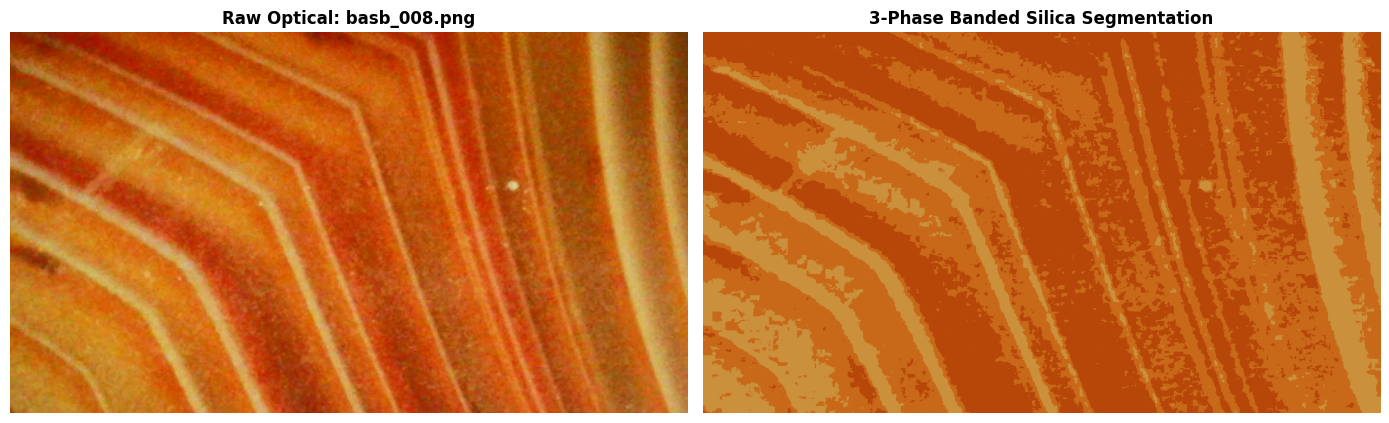

In [6]:
import matplotlib.pyplot as plt

top_path = df_focus.iloc[0]["filepath"]
img = cv2.imread(top_path)
h, w = img.shape[:2]
crop = img[int(h*0.05):int(h*0.95), int(w*0.05):int(w*0.95)]
crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).astype(np.float32)
weights = np.array([0.8, 1.8, 1.5], dtype=np.float32)
weighted_px = (lab * weights).reshape(-1, 3)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(weighted_px)

centers_rgb = np.zeros((3, 3), dtype=np.uint8)
flat_rgb = crop_rgb.reshape(-1, 3)
for i in range(3):
    centers_rgb[i] = np.mean(flat_rgb[labels == i], axis=0).astype(np.uint8)

segmented_rgb = centers_rgb[labels].reshape(crop.shape)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
axs[0].imshow(crop_rgb)
axs[0].set_title(f"Raw Optical: {df_focus.iloc[0]['filename']}", fontweight='bold')
axs[0].axis('off')

axs[1].imshow(segmented_rgb)
axs[1].set_title("3-Phase Banded Silica Segmentation", fontweight='bold')
axs[1].axis('off')

plt.tight_layout()
plt.show()

## Specimen SPEC-0005: Fortification Banded Agate (Akik Sulaiman Besar)

### 1. Rhythmic Micro-Banding Architecture
* **Fortification / Chevron Geometry:** Top-ranked capture `basb_008.png` captures the central chevron fold apex, generating a peak edge gradient of **23.61** and GLCM contrast of **13.35**.
* **Orientation Entropy Invariance:** Angular entropy converged to **0.75 ± 0.00** across all top 12 frames, reflecting the consistent bi-directional symmetry of rhythmic silica crystallization folds.

### 2. Tri-Phase Silica Layer Allocation
* **Dense Carnelian Bands (37.89% ± 10.52%):** Concentrated iron-oxide-rich microcrystalline layers.
* **Amber Chalcedony Groundmass (36.79% ± 5.49%):** Intermediate translucent siliceous transition zones.
* **Cream Silica Micro-Bands (25.32% ± 8.64%):** High-luminance microcrystalline quartz ribbons defining growth periodicity.

In [8]:
import cv2
import json
import pandas as pd

# 1. Load the generated characterization CSV
df_sulaiman = pd.read_csv(r"csv_files\banded_agate_sulaiman_characterization.csv")

# 2. Append to docs/data.json
with open("docs/data.json", "r") as f:
    master_data = json.load(f)

# Clear any prior runs of SPEC-0005 to prevent duplicates
master_data = [row for row in master_data if row.get("specimen_id") != "SPEC-0005"]
master_data.extend(df_sulaiman.to_dict(orient="records"))

with open("docs/data.json", "w") as f:
    json.dump(master_data, f, indent=2)

# 3. Create thumbnail from basb_008
best_frame = "data/raw/banded_agate_sulaiman_big/basb_008.png"
img = cv2.imread(best_frame)
h, w = img.shape[:2]
crop = img[int(h*0.05):int(h*0.95), int(w*0.05):int(w*0.95)]
scale = 480.0 / crop.shape[1]
thumb = cv2.resize(crop, (480, int(crop.shape[0] * scale)), interpolation=cv2.INTER_AREA)

cv2.putText(thumb, "SPEC-0005 / SULAIMAN FORTIFICATION AGATE", (15, thumb.shape[0] - 15),
            cv2.FONT_HERSHEY_SIMPLEX, 0.38, (255, 255, 255), 1, cv2.LINE_AA)
cv2.imwrite("docs/assets/thumbnails/specimen_0005_thumb.jpg", thumb, [cv2.IMWRITE_JPEG_QUALITY, 80])

print(f"Updated docs/data.json with {len(df_sulaiman)} records.")
print("Saved docs/assets/thumbnails/specimen_0005_thumb.jpg")

Updated docs/data.json with 12 records.
Saved docs/assets/thumbnails/specimen_0005_thumb.jpg
